# Notebook 4 — Does It Actually Work? (t-test + Confidence Interval)

**Goal of this notebook:** for each shortlisted pair, test whether the backtested strategy's
average return is really different from zero, or could just be noise.

$$H_0: \mu = 0 \quad \text{vs.} \quad H_1: \mu \neq 0$$

where $\mu$ is the mean daily strategy return over the Verify period.

**On independence:** a plain t-test assumes each day's return is unrelated to the last. Our
strategy holds positions for multiple days in a row, so daily returns during a trade are
correlated with each other — the plain t-test's p-value and confidence interval can be
overconfident here. This notebook runs the naive t-test, then two independence-robust fixes
side by side: **Newey-West standard errors** and a **moving block bootstrap**, so you can see
how much (if at all) the conclusion changes.

In [1]:
!pip install -q statsmodels

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.api as sm

pd.set_option('display.max_rows', 200)
plt.rcParams['figure.dpi'] = 110
np.random.seed(42)  # for reproducible bootstrap results

## 0. Google Drive setup

Reads Notebook 3's output from `03_trading_rule_backtest`, saves this notebook's output to
`04_ttest_ci`.

In [3]:
PARENT_FOLDER_ID = '1w9Q2nfcNhew6hzx8eQSCINReUy3OUwE1'
PREV_NOTEBOOK_FOLDER = '03_trading_rule_backtest'
THIS_NOTEBOOK_FOLDER = '04_ttest_ci'

from google.colab import auth
auth.authenticate_user()

import google.auth
from googleapiclient.discovery import build
from googleapiclient.http import MediaFileUpload, MediaIoBaseDownload
import io

creds, _ = google.auth.default()
drive_service = build('drive', 'v3', credentials=creds)


def get_or_create_subfolder(parent_id, name):
    query = (f"'{parent_id}' in parents and name='{name}' "
             "and mimeType='application/vnd.google-apps.folder' and trashed=false")
    results = drive_service.files().list(q=query, fields='files(id, name)', supportsAllDrives=True, includeItemsFromAllDrives=True).execute()
    files = results.get('files', [])
    if files:
        return files[0]['id']
    metadata = {'name': name, 'mimeType': 'application/vnd.google-apps.folder', 'parents': [parent_id]}
    folder = drive_service.files().create(body=metadata, fields='id', supportsAllDrives=True).execute()
    print(f"Created new Drive subfolder: {name}")
    return folder['id']


def upload_file(local_path, folder_id):
    filename = local_path.split('/')[-1]
    query = f"'{folder_id}' in parents and name='{filename}' and trashed=false"
    results = drive_service.files().list(q=query, fields='files(id, name)', supportsAllDrives=True, includeItemsFromAllDrives=True).execute()
    existing = results.get('files', [])
    media = MediaFileUpload(local_path, resumable=True)
    if existing:
        drive_service.files().update(fileId=existing[0]['id'], media_body=media, supportsAllDrives=True).execute()
    else:
        metadata = {'name': filename, 'parents': [folder_id]}
        drive_service.files().create(body=metadata, media_body=media, fields='id', supportsAllDrives=True).execute()
    print(f"Uploaded {filename} to Drive.")


def download_file(filename, folder_id, local_path=None):
    local_path = local_path or filename
    query = f"'{folder_id}' in parents and name='{filename}' and trashed=false"
    results = drive_service.files().list(q=query, fields='files(id, name)', supportsAllDrives=True, includeItemsFromAllDrives=True).execute()
    files = results.get('files', [])
    if not files:
        raise FileNotFoundError(f"{filename} not found in Drive folder.")
    request = drive_service.files().get_media(fileId=files[0]['id'], supportsAllDrives=True)
    fh = io.FileIO(local_path, 'wb')
    downloader = MediaIoBaseDownload(fh, request)
    done = False
    while not done:
        _, done = downloader.next_chunk()
    print(f"Downloaded {filename} from Drive.")
    return local_path


prev_folder_id = get_or_create_subfolder(PARENT_FOLDER_ID, PREV_NOTEBOOK_FOLDER)
this_folder_id = get_or_create_subfolder(PARENT_FOLDER_ID, THIS_NOTEBOOK_FOLDER)
print(f"Ready — reading from '{PREV_NOTEBOOK_FOLDER}', saving to '{THIS_NOTEBOOK_FOLDER}'.")

Created new Drive subfolder: 04_ttest_ci
Ready — reading from '03_trading_rule_backtest', saving to '04_ttest_ci'.


### Diagnostic: what can this session see in `03_trading_rule_backtest`?

If this comes back empty, re-run the auth cell above and make sure you pick the Google
account that has access to the shared folder.

In [4]:
diag = drive_service.files().list(
    q=f"'{prev_folder_id}' in parents and trashed=false",
    fields='files(id, name, modifiedTime)',
    supportsAllDrives=True,
    includeItemsFromAllDrives=True,
).execute()
found = diag.get('files', [])
print(f"Files visible in '{PREV_NOTEBOOK_FOLDER}':")
for f in found:
    print(f"  - {f['name']}")
if not found:
    print("  (none — check your Google account / re-run Notebook 3)")

Files visible in '03_trading_rule_backtest':
  - backtest_summary.csv
  - daily_strategy_returns.csv
  - all_trades.csv


## 1. Load backtest results from Notebook 3

In [5]:
for fname in ['all_trades.csv', 'daily_strategy_returns.csv', 'backtest_summary.csv']:
    download_file(fname, prev_folder_id)

all_trades = pd.read_csv('all_trades.csv', parse_dates=['entry_date', 'exit_date'])
daily_returns = pd.read_csv('daily_strategy_returns.csv', index_col=0, parse_dates=True)
backtest_summary = pd.read_csv('backtest_summary.csv')

pairs = list(daily_returns.columns)
print(f"Pairs to test: {pairs}")
backtest_summary

Downloaded all_trades.csv from Drive.
Downloaded daily_strategy_returns.csv from Drive.
Downloaded backtest_summary.csv from Drive.
Pairs to test: ['V-MA']


,pair,beta,n_trades,total_return_%,win_rate,avg_trade_return_%
0,V-MA,0.7894,10,11.21,0.9,1.075


## 2. Are daily returns well-behaved? (per pair)

Before trusting any test, look at the data: histogram (shape/normality), QQ plot (formal
normality check), and autocorrelation (the independence question itself).

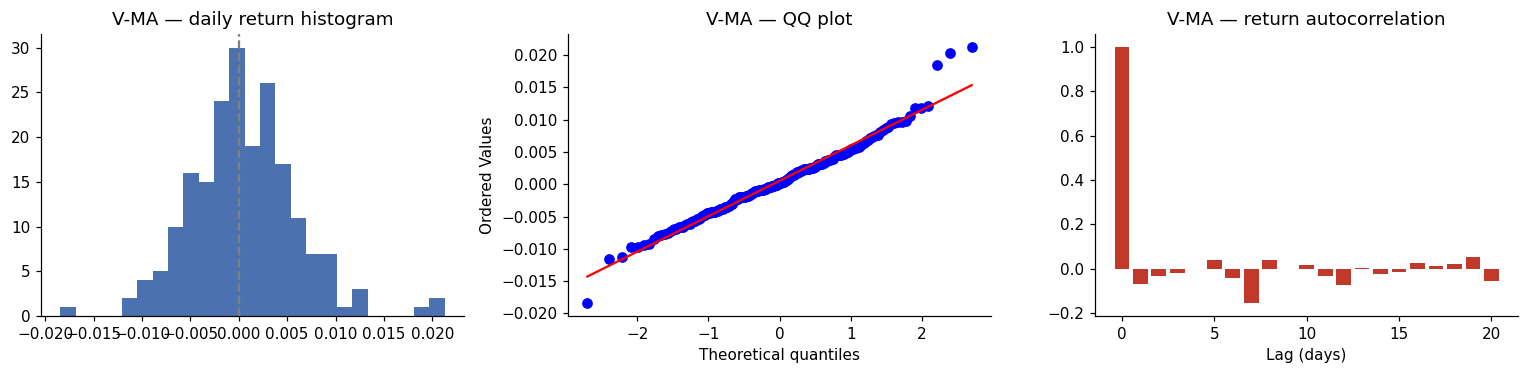

In [6]:
from statsmodels.tsa.stattools import acf

for pair in pairs:
    r = daily_returns[pair].dropna()
    r_nonzero = r[r != 0]  # only days where a position was actually held

    fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))

    axes[0].hist(r_nonzero, bins=25, color='#1f4e9c', alpha=0.8)
    axes[0].axvline(0, color='gray', linestyle='--')
    axes[0].set_title(f'{pair} — daily return histogram')
    axes[0].spines[['top', 'right']].set_visible(False)

    stats.probplot(r_nonzero, dist='norm', plot=axes[1])
    axes[1].set_title(f'{pair} — QQ plot')
    axes[1].spines[['top', 'right']].set_visible(False)

    return_acf = acf(r.fillna(0), nlags=20, fft=True)
    axes[2].bar(range(len(return_acf)), return_acf, color='#c0392b')
    axes[2].set_title(f'{pair} — return autocorrelation')
    axes[2].set_xlabel('Lag (days)')
    axes[2].spines[['top', 'right']].set_visible(False)

    fig.tight_layout()
    plt.show()

## 3. Naive t-test and 95% confidence interval

The standard one-sample t-test, assuming independent daily returns (the assumption we just
visually questioned above).

In [7]:
def naive_ttest(returns):
    returns = returns.dropna().values
    n = len(returns)
    mean = returns.mean()
    se = returns.std(ddof=1) / np.sqrt(n)
    t_stat, p_value = stats.ttest_1samp(returns, 0)
    ci_low, ci_high = stats.t.interval(0.95, df=n - 1, loc=mean, scale=se)
    sharpe = (mean / returns.std(ddof=1)) * np.sqrt(252) if returns.std(ddof=1) > 0 else np.nan
    return {'mean': mean, 'se': se, 't_stat': t_stat, 'p_value': p_value,
            'ci_low': ci_low, 'ci_high': ci_high, 'sharpe_annualized': sharpe, 'n': n}


naive_results = {pair: naive_ttest(daily_returns[pair]) for pair in pairs}
pd.DataFrame(naive_results).T

,mean,se,t_stat,p_value,ci_low,ci_high,sharpe_annualized,n
V-MA,0.000212,0.000156,1.357776,0.175146,-0.000095,0.000518,0.962003,502.0


## 4. Independence fix #1: Newey-West standard errors

Instead of assuming independent daily returns, Newey-West standard errors explicitly allow for
autocorrelation up to some number of lags, widening (or sometimes narrowing) the confidence
interval to reflect the data's actual dependence structure. We fit an intercept-only regression
and ask statsmodels for HAC (heteroskedasticity- and autocorrelation-consistent) standard
errors.

In [8]:
def newey_west_ttest(returns):
    returns = returns.dropna().values
    n = len(returns)
    maxlags = int(np.floor(4 * (n / 100) ** (2 / 9)))  # standard Newey-West rule of thumb
    maxlags = max(maxlags, 1)
    X = np.ones((n, 1))
    model = sm.OLS(returns, X).fit(cov_type='HAC', cov_kwds={'maxlags': maxlags})
    mean = model.params[0]
    se = model.bse[0]
    t_stat = model.tvalues[0]
    p_value = model.pvalues[0]
    ci_low, ci_high = model.conf_int()[0]
    return {'mean': mean, 'se': se, 't_stat': t_stat, 'p_value': p_value,
            'ci_low': ci_low, 'ci_high': ci_high, 'maxlags': maxlags, 'n': n}


nw_results = {pair: newey_west_ttest(daily_returns[pair]) for pair in pairs}
pd.DataFrame(nw_results).T

,mean,se,t_stat,p_value,ci_low,ci_high,maxlags,n
V-MA,0.000212,0.000142,1.488865,0.136523,-0.000067,0.00049,5.0,502.0


## 5. Independence fix #2: moving block bootstrap

Instead of resampling single random days (which would break the day-to-day dependence
entirely), we resample whole **blocks** of consecutive days, preserving short-run dependence
within each block. We rebuild the full return series many times this way and look at the
spread of resulting means.

In [9]:
def moving_block_bootstrap(returns, block_size=20, n_boot=2000):
    returns = returns.dropna().values
    n = len(returns)
    n_blocks_needed = int(np.ceil(n / block_size))
    max_start = n - block_size
    boot_means = np.empty(n_boot)

    for b in range(n_boot):
        starts = np.random.randint(0, max_start + 1, size=n_blocks_needed)
        sample = np.concatenate([returns[s:s + block_size] for s in starts])[:n]
        boot_means[b] = sample.mean()

    ci_low, ci_high = np.percentile(boot_means, [2.5, 97.5])
    return boot_means, ci_low, ci_high


bootstrap_results = {}
for pair in pairs:
    boot_means, ci_low, ci_high = moving_block_bootstrap(daily_returns[pair])
    bootstrap_results[pair] = {
        'boot_means': boot_means,
        'mean': boot_means.mean(),
        'ci_low': ci_low,
        'ci_high': ci_high,
    }

pd.DataFrame({p: {'mean': r['mean'], 'ci_low': r['ci_low'], 'ci_high': r['ci_high']}
              for p, r in bootstrap_results.items()}).T

,mean,ci_low,ci_high
V-MA,0.000233,0.000007,0.000468


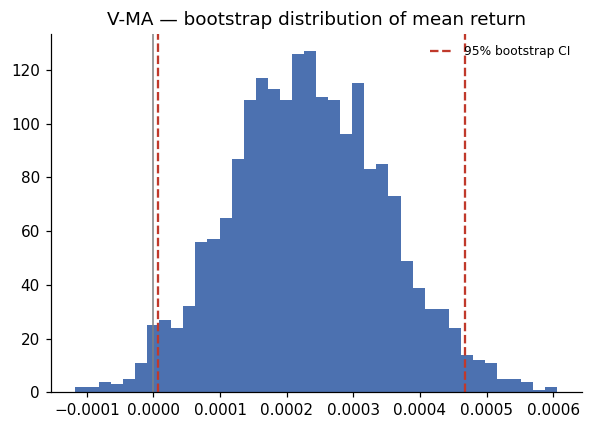

In [10]:
fig, axes = plt.subplots(1, len(pairs), figsize=(5.5 * len(pairs), 4), squeeze=False)
axes = axes[0]

for ax, pair in zip(axes, pairs):
    boot_means = bootstrap_results[pair]['boot_means']
    ci_low, ci_high = bootstrap_results[pair]['ci_low'], bootstrap_results[pair]['ci_high']
    ax.hist(boot_means, bins=40, color='#1f4e9c', alpha=0.8)
    ax.axvline(ci_low, color='#c0392b', linestyle='--', label='95% bootstrap CI')
    ax.axvline(ci_high, color='#c0392b', linestyle='--')
    ax.axvline(0, color='gray', linewidth=1)
    ax.set_title(f'{pair} — bootstrap distribution of mean return')
    ax.legend(fontsize=8, frameon=False)
    ax.spines[['top', 'right']].set_visible(False)

fig.tight_layout()
plt.show()

## 6. Compare all three methods side by side

This is the key comparison for the write-up: does accounting for dependence change whether we
conclude the strategy's return is real?

In [11]:
comparison_rows = []
for pair in pairs:
    comparison_rows.append({
        'pair': pair,
        'mean_daily_return': naive_results[pair]['mean'],
        'naive_p_value': naive_results[pair]['p_value'],
        'naive_ci': (round(naive_results[pair]['ci_low'], 6), round(naive_results[pair]['ci_high'], 6)),
        'newey_west_p_value': nw_results[pair]['p_value'],
        'newey_west_ci': (round(nw_results[pair]['ci_low'], 6), round(nw_results[pair]['ci_high'], 6)),
        'bootstrap_ci': (round(bootstrap_results[pair]['ci_low'], 6), round(bootstrap_results[pair]['ci_high'], 6)),
        'sharpe_annualized': naive_results[pair]['sharpe_annualized'],
    })

comparison_df = pd.DataFrame(comparison_rows)
comparison_df

,pair,mean_daily_return,naive_p_value,naive_ci,newey_west_p_value,newey_west_ci,bootstrap_ci,sharpe_annualized
0,V-MA,0.000212,0.175146,"(-9.5e-05, 0.000518)",0.136523,"(-6.7e-05, 0.00049)","(7e-06, 0.000468)",0.962003


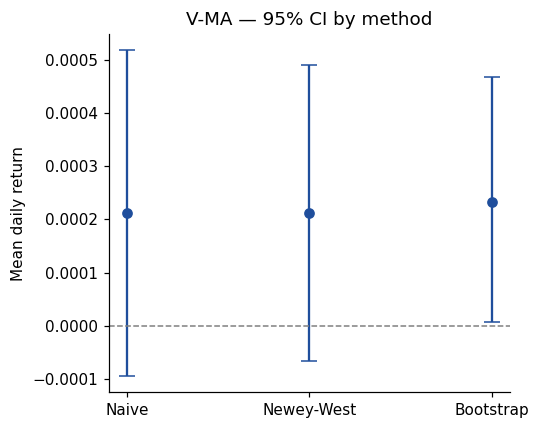

In [12]:
# Visual comparison: CI width/position across the three methods, per pair
fig, axes = plt.subplots(1, len(pairs), figsize=(5 * len(pairs), 4), squeeze=False)
axes = axes[0]

methods = ['Naive', 'Newey-West', 'Bootstrap']
for ax, pair in zip(axes, pairs):
    means = [naive_results[pair]['mean'], nw_results[pair]['mean'], bootstrap_results[pair]['mean']]
    los = [naive_results[pair]['ci_low'], nw_results[pair]['ci_low'], bootstrap_results[pair]['ci_low']]
    his = [naive_results[pair]['ci_high'], nw_results[pair]['ci_high'], bootstrap_results[pair]['ci_high']]
    errs = [[m - l for m, l in zip(means, los)], [h - m for h, m in zip(his, means)]]

    ax.errorbar(range(3), means, yerr=errs, fmt='o', color='#1f4e9c', capsize=5)
    ax.axhline(0, color='gray', linestyle='--', linewidth=1)
    ax.set_xticks(range(3))
    ax.set_xticklabels(methods)
    ax.set_title(f'{pair} — 95% CI by method')
    ax.set_ylabel('Mean daily return')
    ax.spines[['top', 'right']].set_visible(False)

fig.tight_layout()
plt.show()

## 7. Save results for Notebook 5

In [13]:
comparison_df.to_csv('hypothesis_test_comparison.csv', index=False)
upload_file('hypothesis_test_comparison.csv', this_folder_id)

print(f"Saved locally and uploaded to Drive ({THIS_NOTEBOOK_FOLDER}): hypothesis_test_comparison.csv")

Uploaded hypothesis_test_comparison.csv to Drive.
Saved locally and uploaded to Drive (04_ttest_ci): hypothesis_test_comparison.csv


## Next notebook

**Notebook 5** backtests a pair that looked significant naively but did **not** survive
Bonferroni correction (e.g., V-MA), runs the same hypothesis tests on it, and compares its
performance against the corrected pairs — the core "does correction matter" comparison.